In [1]:
import time
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

SEED = 123
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_default_dtype(torch.float64)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

MU = 10.0
X0 = 1.0
V0 = 0.0

PERIOD_MARGIN = 1.15
ROUGH_PERIOD_FACTOR = 1.614
N_PERIODS_SETTLE = 4

LAYERS = (1, 32, 32, 32, 32, 1)
WINDOW_SIZE = 2.0            # only used as a fallback / reference scale
N_WINDOWS_TARGET = 10        # equidistribution target for non-uniform placement

N_COLLOCATION_PER_WINDOW = 2000
COLLOCATION_SCALE_CAP = 3.0
ADAM_EPOCHS = 3000
ADAM_LR = 1e-3
GRAD_CLIP_NORM = 10.0
LBFGS_MAX_ITER = 2000
PRINT_EVERY = 500

OMEGA_0 = 10.0   # justified in v1's omega_0 trial

# Adaptive collocation resampling
RESAMPLE_EVERY = 500
RESAMPLE_CANDIDATE_MULT = 5
RESAMPLE_UNIFORM_FLOOR = 0.2

# Non-uniform window placement
COARSE_N_POINTS = 4000
MIN_WINDOW_WIDTH = 0.15
MAX_WINDOW_WIDTH = 3.0
MONITOR_VELOCITY_WEIGHT = 0.4
MONITOR_ACCEL_WEIGHT = 0.6

# Convergence retry
LOSS_CONVERGENCE_THRESHOLD = 1e-4
MAX_RETRIES_PER_WINDOW = 2

Using device: cuda


In [2]:
def van_der_pol_rhs(t, y, mu=MU):
    x, v = y
    return [v, mu * (1 - x**2) * v - x]

def estimate_vdp_period(mu, x0=X0, v0=V0, rough_factor=ROUGH_PERIOD_FACTOR, n_settle=N_PERIODS_SETTLE):
    rough_T = rough_factor * mu
    t_span = n_settle * max(rough_T, 5.0)

    def event_peak(t, y):
        return y[1]
    event_peak.direction = -1

    sol = solve_ivp(
        lambda t, y: van_der_pol_rhs(t, y, mu=mu),
        [0.0, t_span], [x0, v0], events=event_peak,
        rtol=1e-10, atol=1e-12, max_step=0.05
    )
    peak_times = sol.t_events[0]
    if len(peak_times) < 3:
        print(f"[period detection] mu={mu}: not enough peaks found, falling back to rough estimate {rough_T:.3f}")
        return rough_T
    return peak_times[-1] - peak_times[-2]

vdp_period = estimate_vdp_period(MU)
T_FINAL = float(PERIOD_MARGIN * vdp_period)
print(f"Detected VdP period at mu={MU}: {vdp_period:.4f} -> T_FINAL = {T_FINAL:.4f}")

Detected VdP period at mu=10.0: 19.0784 -> T_FINAL = 21.9401


In [3]:
# Cell 3: PINN Architectures (same as v1)
class BasePINN(nn.Module):
    def __init__(self):
        super().__init__()

    def encode_input(self, t):
        raise NotImplementedError("Subclasses must implement encode_input().")

    def trunk_forward(self, encoded):
        raise NotImplementedError("Subclasses must implement trunk_forward().")

    def forward(self, t):
        encoded = self.encode_input(t)
        return self.trunk_forward(encoded)


class SirenPINN(BasePINN):
    def __init__(self, t_start, window_size, layers=LAYERS, omega_0=OMEGA_0):
        super().__init__()
        self.t_start = t_start
        self.window_size = window_size
        self.omega_0 = omega_0

        self.trunk = nn.ModuleList()
        for i in range(len(layers) - 1):
            linear = nn.Linear(layers[i], layers[i + 1])
            with torch.no_grad():
                if i == 0:
                    linear.weight.uniform_(-1 / layers[i], 1 / layers[i])
                else:
                    c = np.sqrt(6 / layers[i]) / self.omega_0
                    linear.weight.uniform_(-c, c)
                linear.bias.zero_()
            self.trunk.append(linear)

    def encode_input(self, t):
        tau = t - self.t_start
        return (2.0 * tau / self.window_size) - 1.0

    def trunk_forward(self, encoded):
        out = encoded
        for layer in self.trunk[:-1]:
            out = torch.sin(self.omega_0 * layer(out))
        return self.trunk[-1](out)


class WindowPINN(nn.Module):
    # Hard-enforces this window's IC: x(t) = x0_local + v0_local*tau + tau^2 * base_model(t).
    def __init__(self, base_model, t_start, window_size, x0_local, v0_local):
        super().__init__()
        self.base_model = base_model
        self.t_start = t_start
        self.window_size = window_size
        self.x0_local = x0_local
        self.v0_local = v0_local

    def forward(self, t):
        tau = t - self.t_start
        n_raw = self.base_model(t)
        return self.x0_local + self.v0_local * tau + (tau ** 2) * n_raw


In [4]:
def physics_residual(model, t, mu=MU):
    x = model(t)
    x_t = torch.autograd.grad(x, t, grad_outputs=torch.ones_like(x), create_graph=True, retain_graph=True)[0]
    x_tt = torch.autograd.grad(x_t, t, grad_outputs=torch.ones_like(x_t), create_graph=True, retain_graph=True)[0]
    return x_tt - mu * (1.0 - x ** 2) * x_t + x

def compute_loss(model, t_f):
    f_pred = physics_residual(model, t_f)
    return torch.mean(f_pred ** 2)

def sample_collocation_points(t_start, t_end, n):
    t_f = np.random.uniform(low=t_start, high=t_end, size=(n, 1))
    t_f = torch.tensor(t_f, dtype=torch.get_default_dtype(), device=device)
    t_f.requires_grad_(True)
    return t_f

def evaluate_state(model, t_value):
    t_tensor = torch.tensor([[t_value]], dtype=torch.get_default_dtype(), device=device, requires_grad=True)
    x = model(t_tensor)
    x_t = torch.autograd.grad(x, t_tensor, grad_outputs=torch.ones_like(x))[0]
    return x.item(), x_t.item()


In [5]:
def adaptive_collocation_points(model, t_start, t_end, n_points, n_candidates_mult=RESAMPLE_CANDIDATE_MULT, uniform_floor=RESAMPLE_UNIFORM_FLOOR):
    n_candidates = max(n_points * n_candidates_mult, n_points)
    t_candidates_np = np.random.uniform(t_start, t_end, size=(n_candidates, 1))
    t_candidates = torch.tensor(t_candidates_np, dtype=torch.get_default_dtype(), device=device)
    t_candidates.requires_grad_(True)
    residual = physics_residual(model, t_candidates)
    scores = (residual.detach() ** 2).cpu().numpy().flatten()
    scores += 1e-12
    probs = scores / scores.sum()

    n_weighted = int(round(n_points * (1.0 - uniform_floor)))
    n_uniform = n_points - n_weighted
    weighted_idx = np.random.choice(n_candidates, size=n_weighted, replace=False, p=probs)
    t_weighted_np = t_candidates_np[weighted_idx]
    t_uniform_np = np.random.uniform(t_start, t_end, size=(n_uniform, 1))
    t_new_np = np.vstack([t_weighted_np, t_uniform_np])
    t_new = torch.tensor(t_new_np, dtype=torch.get_default_dtype(), device=device)
    t_new.requires_grad_(True)
    return t_new

def compute_nonuniform_window_edges(n_windows, t_final=T_FINAL, mu=MU, x0=X0, v0=V0, coarse_n_points=COARSE_N_POINTS, min_width=MIN_WINDOW_WIDTH, max_width=MAX_WINDOW_WIDTH):
    t_coarse = np.linspace(0.0, t_final, coarse_n_points)
    sol = solve_ivp(lambda t, y: van_der_pol_rhs(t, y, mu=mu), [0.0, t_final], [x0, v0],
                     t_eval=t_coarse, method="RK45", rtol=1e-9, atol=1e-9)
    x_c, v_c = sol.y[0], sol.y[1]
    accel = mu * (1 - x_c ** 2) * v_c - x_c
    vel_norm = np.abs(v_c) / (np.abs(v_c).max() + 1e-12)
    acc_norm = np.abs(accel) / (np.abs(accel).max() + 1e-12)
    monitor = MONITOR_VELOCITY_WEIGHT * vel_norm + MONITOR_ACCEL_WEIGHT * acc_norm

    cumulative = np.concatenate([[0.0], np.cumsum(0.5 * (monitor[1:] + monitor[:-1]) * np.diff(t_coarse))])
    total_measure = cumulative[-1]
    targets = np.linspace(0.0, total_measure, n_windows + 1)
    edges = np.interp(targets, cumulative, t_coarse)
    edges[0], edges[-1] = 0.0, t_final

    # forward pass: enforce MIN_WINDOW_WIDTH left to right
    for i in range(1, len(edges) - 1):
        if edges[i] - edges[i - 1] < min_width:
            edges[i] = edges[i - 1] + min_width
    edges = np.clip(edges, 0.0, t_final)
    edges[-1] = t_final
    # backward pass: re-enforce from the right so the last window can't collapse below the floor
    for i in range(len(edges) - 2, 0, -1):
        if edges[i + 1] - edges[i] < min_width:
            edges[i] = edges[i + 1] - min_width
    edges = np.clip(edges, 0.0, t_final)
    edges[0], edges[-1] = 0.0, t_final

    edges = np.unique(edges)
    capped_edges = [edges[0]]
    for i in range(len(edges) - 1):
        left, right = edges[i], edges[i + 1]
        width = right - left
        if width > max_width:
            n_sub = int(np.ceil(width / max_width))
            sub_edges = np.linspace(left, right, n_sub + 1)[1:]
            capped_edges.extend(sub_edges.tolist())
        else:
            capped_edges.append(right)
    edges = np.unique(np.array(capped_edges))

    return edges, t_coarse, monitor

In [6]:
def run_adam_phase(model, t_start, t_end, n_points, adam_epochs, window_idx, tag="Adam"):
    t_f = sample_collocation_points(t_start, t_end, n_points)
    history = []
    optimizer = torch.optim.Adam(model.parameters(), lr=ADAM_LR)
    for epoch in range(adam_epochs):
        if epoch > 0 and epoch % RESAMPLE_EVERY == 0:
            t_f = adaptive_collocation_points(model, t_start, t_end, n_points)
        optimizer.zero_grad()
        loss = compute_loss(model, t_f)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP_NORM)
        optimizer.step()
        history.append(loss.item())
        if epoch % PRINT_EVERY == 0:
            print(f"[window {window_idx}] [{tag}]  epoch {epoch:5d} | loss {loss.item():.3e}")
    return history, t_f

def run_lbfgs_phase(model, t_f, max_iter, window_idx, tag="L-BFGS"):
    history = []
    optimizer_lbfgs = torch.optim.LBFGS(model.parameters(), max_iter=max_iter, tolerance_grad=1e-9,
                                         tolerance_change=1e-12, history_size=50, line_search_fn="strong_wolfe")
    counter = {"n": 0}

    def closure():
        optimizer_lbfgs.zero_grad()
        loss = compute_loss(model, t_f)
        loss.backward()
        history.append(loss.item())
        counter["n"] += 1
        if counter["n"] % PRINT_EVERY == 0:
            print(f"[window {window_idx}] [{tag}] iter {counter['n']:5d} | loss {loss.item():.3e}")
        return loss

    optimizer_lbfgs.step(closure)
    return history

In [7]:
def train_window(model, t_start, t_end, n_points, adam_epochs, window_idx=0):
    history, t_f = run_adam_phase(model, t_start, t_end, n_points, adam_epochs, window_idx, tag="Adam")
    t_f = adaptive_collocation_points(model, t_start, t_end, n_points)
    history += run_lbfgs_phase(model, t_f, LBFGS_MAX_ITER, window_idx, tag="L-BFGS")

    retries = 0
    while history[-1] > LOSS_CONVERGENCE_THRESHOLD and retries < MAX_RETRIES_PER_WINDOW:
        retries += 1
        print(f"[window {window_idx}] loss {history[-1]:.3e} > {LOSS_CONVERGENCE_THRESHOLD:.1e} "
              f"threshold -> retry {retries}/{MAX_RETRIES_PER_WINDOW}")
        t_f = adaptive_collocation_points(model, t_start, t_end, n_points)
        history += run_lbfgs_phase(model, t_f, LBFGS_MAX_ITER, window_idx, tag=f"L-BFGS-retry{retries}")

    return history

In [8]:
window_edges, coarse_t, coarse_monitor = compute_nonuniform_window_edges(N_WINDOWS_TARGET)
window_widths = np.diff(window_edges)
n_windows = len(window_widths)
print(f"Non-uniform window edges (t): {np.round(window_edges, 3)}")
print(f"Window widths: {np.round(window_widths, 3)}")
print(f"Window count: {n_windows} (target was {N_WINDOWS_TARGET}, "
      f"grew due to MAX_WINDOW_WIDTH={MAX_WINDOW_WIDTH} subdivision)")
print(f"Max window width after capping: {window_widths.max():.3f} (cap={MAX_WINDOW_WIDTH})")

mean_width = window_widths.mean()

Non-uniform window edges (t): [ 0.     0.89   1.04   1.19   3.459  5.729  7.998 10.268 10.418 10.568
 13.536 16.504 19.472 19.886 20.036 21.94 ]
Window widths: [0.89  0.15  0.15  2.27  2.27  2.27  2.27  0.15  0.15  2.968 2.968 2.968
 0.414 0.15  1.904]
Window count: 15 (target was 10, grew due to MAX_WINDOW_WIDTH=3.0 subdivision)
Max window width after capping: 2.968 (cap=3.0)


In [9]:
start_time = time.time()
models = []
full_history = []
x0_cur, v0_cur = X0, V0

for w in range(n_windows):
    t_start = float(window_edges[w])
    t_end = float(window_edges[w + 1])
    width = t_end - t_start

    # scale collocation points and Adam epochs by window width relative to the mean
    width_ratio = width / mean_width
    n_points_w = int(round(N_COLLOCATION_PER_WINDOW * np.clip(width_ratio, 1.0, COLLOCATION_SCALE_CAP)))
    adam_epochs_w = int(round(ADAM_EPOCHS * np.clip(width_ratio, 1.0, 2.0)))

    print(f"\n--- Training Window {w+1}/{n_windows} [t={t_start:.2f} to {t_end:.2f}] "
          f"(n_points={n_points_w}, adam_epochs={adam_epochs_w}) ---")

    base = SirenPINN(t_start, window_size=width, omega_0=OMEGA_0).to(device)
    model_w = WindowPINN(base, t_start, width, x0_cur, v0_cur).to(device)
    if w > 0:
        model_w.base_model.load_state_dict(models[-1].base_model.state_dict())

    hist = train_window(model_w, t_start, t_end, n_points_w, adam_epochs_w, window_idx=w)
    full_history.extend(hist)

    x0_cur, v0_cur = evaluate_state(model_w, t_end)
    models.append(model_w)

training_time = time.time() - start_time
print(f"\nTime-Marching Training Complete! ({training_time:.1f}s)")


--- Training Window 1/15 [t=0.00 to 0.89] (n_points=2000, adam_epochs=3000) ---
[window 0] [Adam]  epoch     0 | loss 2.824e+02
[window 0] [Adam]  epoch   500 | loss 2.027e-01
[window 0] [Adam]  epoch  1000 | loss 1.957e-01
[window 0] [Adam]  epoch  1500 | loss 2.710e-01
[window 0] [Adam]  epoch  2000 | loss 2.942e-01
[window 0] [Adam]  epoch  2500 | loss 3.775e-01
[window 0] [L-BFGS] iter   500 | loss 1.734e-05
[window 0] [L-BFGS] iter  1000 | loss 2.737e-06
[window 0] [L-BFGS] iter  1500 | loss 8.550e-07
[window 0] [L-BFGS] iter  2000 | loss 8.518e-07

--- Training Window 2/15 [t=0.89 to 1.04] (n_points=2000, adam_epochs=3000) ---
[window 1] [Adam]  epoch     0 | loss 4.748e+03
[window 1] [Adam]  epoch   500 | loss 3.248e+03
[window 1] [Adam]  epoch  1000 | loss 8.848e+02
[window 1] [Adam]  epoch  1500 | loss 6.674e+02
[window 1] [Adam]  epoch  2000 | loss 5.276e+02
[window 1] [Adam]  epoch  2500 | loss 5.073e+02
[window 1] [L-BFGS] iter   500 | loss 4.647e+01
[window 1] [L-BFGS] it

In [10]:
t_eval = np.linspace(0, T_FINAL, 2000)
sol = solve_ivp(van_der_pol_rhs, [0, T_FINAL], [X0, V0], t_eval=t_eval, method="RK45", rtol=1e-10, atol=1e-10)
x_reference = sol.y[0]
v_reference = sol.y[1]

x_pred = np.zeros_like(t_eval)
for w, model_w in enumerate(models):
    t_start, t_end = window_edges[w], window_edges[w + 1]
    mask = (t_eval >= t_start) & (t_eval <= t_end + 1e-9)
    if not np.any(mask):
        continue
    t_local = torch.tensor(t_eval[mask].reshape(-1, 1), dtype=torch.get_default_dtype(), device=device)
    with torch.no_grad():
        x_pred[mask] = model_w(t_local).cpu().numpy().flatten()

mse = np.mean((x_pred - x_reference) ** 2)
relative_l2_error = np.linalg.norm(x_pred - x_reference) / np.linalg.norm(x_reference)
final_training_loss = full_history[-1]
n_params = sum(p.numel() for p in models[0].parameters())

t_res_test = torch.tensor(np.random.uniform(0.0, T_FINAL, size=(2000, 1)), dtype=torch.get_default_dtype(), device=device)
residual_vals = []
for w, model_w in enumerate(models):
    t_start, t_end = window_edges[w], window_edges[w + 1]
    mask_np = (t_res_test.detach().cpu().numpy().flatten() >= t_start) & (t_res_test.detach().cpu().numpy().flatten() <= t_end)
    if not np.any(mask_np):
        continue
    t_sub = t_res_test[mask_np].clone().detach().requires_grad_(True)
    f_sub = physics_residual(model_w, t_sub)
    residual_vals.append(f_sub.detach().cpu().numpy())
mean_physics_residual = np.mean(np.concatenate(residual_vals) ** 2) if residual_vals else float("nan")

# Calculate additional metrics
mae = np.mean(np.abs(x_pred - x_reference))
max_error = np.max(np.abs(x_pred - x_reference))
rmse = np.sqrt(mse)

print(f"MSE: {mse:.3e}")
print(f"RMSE: {rmse:.3e}")
print(f"MAE: {mae:.3e}")
print(f"Max Error (L_inf): {max_error:.3e}")
print(f"Relative L2 error: {relative_l2_error:.3e}")
print(f"Final training loss: {final_training_loss:.3e}")
print(f"Mean physics residual (test points): {mean_physics_residual:.3e}")
print(f"Training time: {training_time:.1f}s")
print(f"Trainable parameters (per window model): {n_params}")
print(f"Windows: {n_windows}")

MSE: 2.200e-05
RMSE: 4.690e-03
MAE: 1.150e-03
Max Error (L_inf): 5.479e-02
Relative L2 error: 2.884e-03
Final training loss: 1.823e-04
Mean physics residual (test points): 2.364e-04
Training time: 1254.7s
Trainable parameters (per window model): 3265
Windows: 15


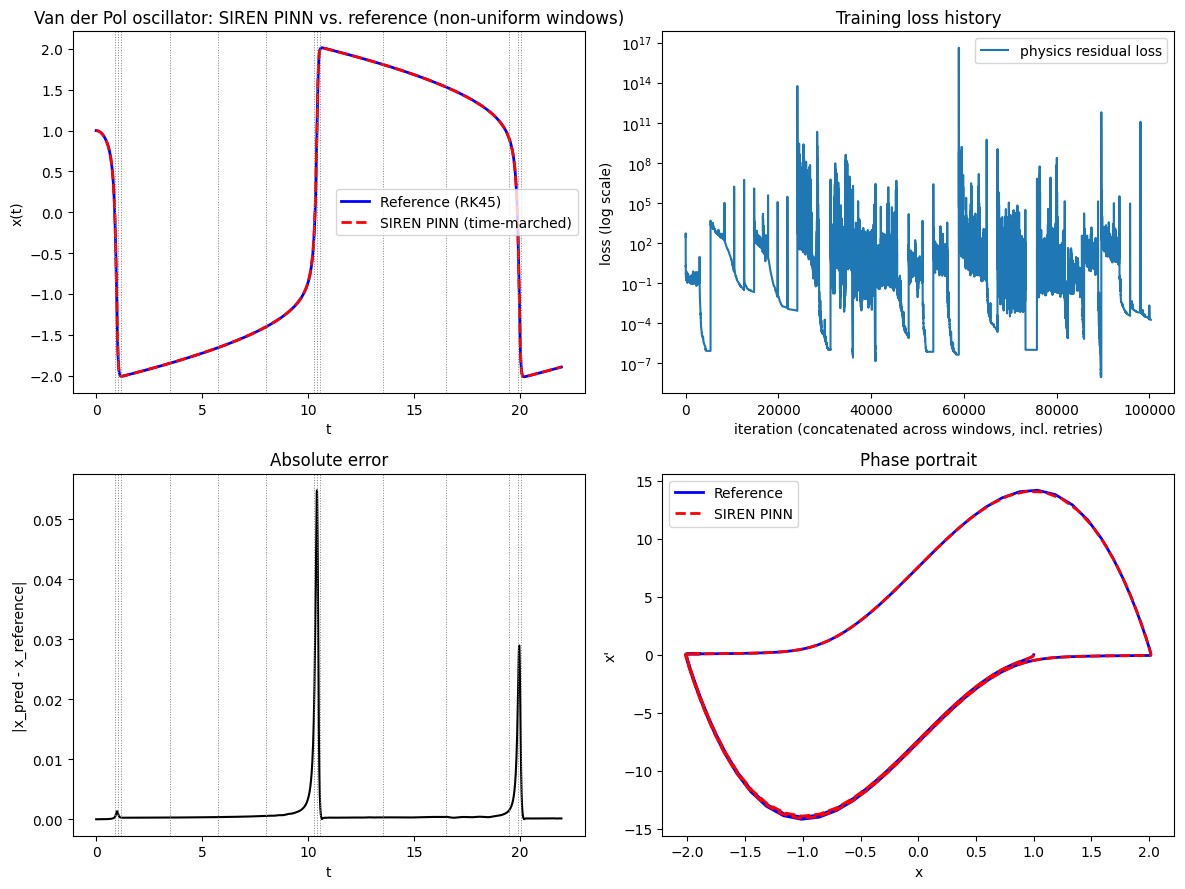

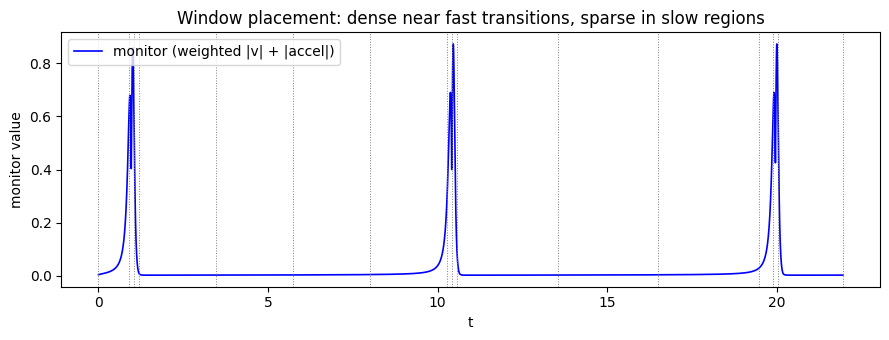

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

axes[0, 0].plot(t_eval, x_reference, "b-", linewidth=2, label="Reference (RK45)")
axes[0, 0].plot(t_eval, x_pred, "r--", linewidth=2, label="SIREN PINN (time-marched)")
for edge in window_edges[1:-1]:
    axes[0, 0].axvline(edge, color="gray", linestyle=":", linewidth=0.7)
axes[0, 0].set_xlabel("t")
axes[0, 0].set_ylabel("x(t)")
axes[0, 0].set_title("Van der Pol oscillator: SIREN PINN vs. reference (non-uniform windows)")
axes[0, 0].legend()

axes[0, 1].semilogy(full_history, label="physics residual loss")
axes[0, 1].set_xlabel("iteration (concatenated across windows, incl. retries)")
axes[0, 1].set_ylabel("loss (log scale)")
axes[0, 1].set_title("Training loss history")
axes[0, 1].legend()

axes[1, 0].plot(t_eval, np.abs(x_pred - x_reference), "k-")
for edge in window_edges[1:-1]:
    axes[1, 0].axvline(edge, color="gray", linestyle=":", linewidth=0.7)
axes[1, 0].set_xlabel("t")
axes[1, 0].set_ylabel("|x_pred - x_reference|")
axes[1, 0].set_title("Absolute error")

x_pred_dot = np.gradient(x_pred, t_eval)
axes[1, 1].plot(x_reference, v_reference, "b-", linewidth=2, label="Reference")
axes[1, 1].plot(x_pred, x_pred_dot, "r--", linewidth=2, label="SIREN PINN")
axes[1, 1].set_xlabel("x")
axes[1, 1].set_ylabel("x'")
axes[1, 1].set_title("Phase portrait")
axes[1, 1].legend()

plt.tight_layout()
plt.show()

fig2, ax2 = plt.subplots(figsize=(9, 3.5))
ax2.plot(coarse_t, coarse_monitor, "b-", linewidth=1.2, label="monitor (weighted |v| + |accel|)")
for edge in window_edges:
    ax2.axvline(edge, color="gray", linestyle=":", linewidth=0.7)
ax2.set_xlabel("t")
ax2.set_ylabel("monitor value")
ax2.set_title("Window placement: dense near fast transitions, sparse in slow regions")
ax2.legend()
plt.tight_layout()
plt.show()